# Workshop 6 — Medical Domain Adaptation
## 01. Exploratory Data Analysis — MIT-BIH Arrhythmia Database

**Course:** Machine Learning — Semester 2026-III
**Team:** Group 1 — Housing Price Prediction → Medical Adaptation
**Authors:** Miguel Alejandro Chávez Porras, Luisa Fernanda Guerrero Ordoñez, Dilan Stive Arboleda Zambrano

This notebook documents the exploratory analysis of the **MIT-BIH Arrhythmia Database**,
the medical dataset selected for Workshop 6. It connects the data pipeline implemented in
`src/medical_preprocessing.py` with the clinical questions that motivate the medical
adaptation: can the supervised, unsupervised, and generative techniques developed in
Workshops 1–5 be transferred to cardiac arrhythmia detection?

The MIT-BIH Arrhythmia Database (Moody & Mark, 2001) is a canonical benchmark for
ECG beat classification. It contains 48 half-hour two-lead ECG recordings from 47 patients,
sampled at 360 Hz and annotated beat-by-beat by cardiologists. Beat labels follow the
AAMI EC57 superclass convention: **N** (normal), **S** (supraventricular ectopic),
**V** (ventricular ectopic), **F** (fusion). Paced and unclassifiable beats (class **Q**
in the AAMI standard) are excluded because they reflect device-driven rhythms rather than
pathological arrhythmias.

In [38]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from medical_preprocessing import FEATURE_COLUMNS, load_splits
from medical_visualization import (
    plot_class_distribution,
    plot_ecg_segment,
    plot_representative_beats,
    plot_feature_distributions,
    plot_feature_correlation,
    save_figure,
)

# Reproducibility
np.random.seed(42)
sns.set_theme(style="whitegrid", context="notebook")

print("Imports OK. Seed fixed to 42.")

Imports OK. Seed fixed to 42.


## 1. Dataset Overview

The preprocessed feature matrix contains one row per valid heartbeat, with seven
tabular features engineered around the QRS complex and the RR interval sequence.
Splits are patient-level (no beat leakage), stratified by per-record abnormality rate.

In [39]:
# Load the preprocessed feature matrix
df = pd.read_csv("../data/features_mitdb.csv")
df["record_id"] = df["record_id"].astype(str)  # ensure string type

# Load patient-level splits
splits = load_splits("../data/splits_medical.json")

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(f"\nUnique records: {df['record_id'].nunique()}")
print(f"Total beats: {len(df):,}")
print(f"\nMissing values per column:\n{df.isna().sum()}")

Shape: (101297, 12)
Columns: ['rr_prev', 'rr_next', 'rr_ratio', 'qrs_width', 'qrs_amplitude', 'qrs_energy', 'rr_sdnn', 'rr_rmssd', 'label_aami', 'label_binary', 'record_id', 'beat_index']

Unique records: 48
Total beats: 101,297

Missing values per column:
rr_prev          0
rr_next          0
rr_ratio         0
qrs_width        0
qrs_amplitude    0
qrs_energy       0
rr_sdnn          0
rr_rmssd         0
label_aami       0
label_binary     0
record_id        0
beat_index       0
dtype: int64


### 1.1 Feature Summary

All seven tabular features are continuous. Note that `rr_sdnn` and `rr_rmssd` are
computed at the record level (heart-rate variability features), so they are constant
within a patient and act as a patient-level signal rather than a beat-level one.

In [40]:
df[FEATURE_COLUMNS].describe().T

,count,mean,std,min,25%,50%,75%,max
rr_prev,101297.0,0.847276,3.384064,0.250000,0.647222,0.747222,0.905556,834.500000
rr_next,101297.0,0.846420,3.362834,0.250000,0.647222,0.747222,0.905556,834.500000
rr_ratio,101297.0,1.046591,0.733371,0.001990,0.968000,1.003861,1.043333,89.114286
qrs_width,101297.0,74.277294,111.918717,4.000000,8.000000,13.000000,125.000000,400.000000
qrs_amplitude,101297.0,1.614575,0.621599,0.095000,1.147500,1.605000,2.050000,8.820000
qrs_energy,101297.0,127.294758,164.460695,0.950950,35.434750,62.981895,171.309357,9930.371094
rr_sdnn,101297.0,0.350669,3.252727,0.021753,0.053328,0.092498,0.190824,93.042824
rr_rmssd,101297.0,0.414124,3.245986,0.019128,0.048453,0.107147,0.244673,89.572317


## 2. Class Distribution

Class imbalance is the central challenge of medical anomaly detection: arrhythmias are
rare by definition, and a classifier that predicts "normal" for every beat would achieve
high accuracy while being clinically useless (it would never catch a true arrhythmia).

The binary distribution below quantifies this imbalance at the beat level. The AAMI
superclass breakdown shows which arrhythmia families are represented and in what
proportion — information that will drive the choice of class weighting (Workshop 2
transfer) and the need for synthetic augmentation (Workshop 5 GAN transfer).

=== Binary class distribution ===
Normal    (label=0):  90,488 beats (89.3294%)
Abnormal  (label=1):  10,809 beats (10.6706%)

Imbalance ratio (Normal:Abnormal) = 8.37 : 1

=== AAMI superclass distribution ===
N:  90,488 beats (89.3294%)
S:   2,779 beats (2.7434%)
V:   7,228 beats (7.1355%)
F:     802 beats (0.7917%)
[save_figure] Saved to ..\results\figures\01_class_distribution.png


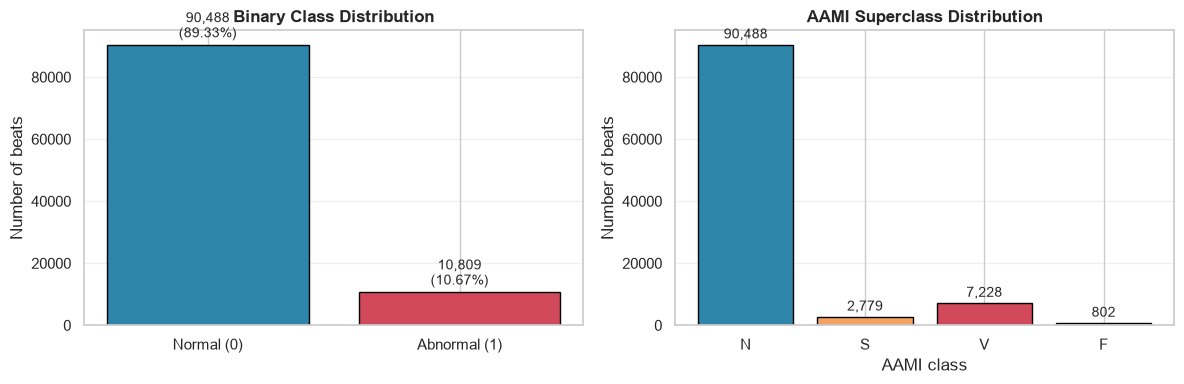

In [41]:
# Global class balance
binary_counts = df["label_binary"].value_counts().sort_index()
aami_counts = df["label_aami"].value_counts().reindex(["N", "S", "V", "F"]).fillna(0).astype(int)

print("=== Binary class distribution ===")
for val, name in [(0, "Normal"), (1, "Abnormal")]:
    n = binary_counts.get(val, 0)
    print(f"{name:9s} (label={val}): {n:>7,} beats ({n/len(df):.4%})")

print(f"\nImbalance ratio (Normal:Abnormal) = {binary_counts[0] / binary_counts[1]:.2f} : 1")

print("\n=== AAMI superclass distribution ===")
for cls, n in aami_counts.items():
    print(f"{cls}: {n:>7,} beats ({n/len(df):.4%})")

# Figure
fig = plot_class_distribution(df)
save_figure(fig, "../results/figures/01_class_distribution.png")
plt.show()

### 2.1 Per-Split Balance

Because splits are patient-level, global balance does not guarantee that each split is
representative. The table below verifies that train/val/test preserve similar abnormality
rates — otherwise threshold tuning on validation would be unreliable.

In [42]:
rows = []
for name, recs in [
    ("Train", splits.train_records),
    ("Val",   splits.val_records),
    ("Test",  splits.test_records),
]:
    sub = df[df["record_id"].isin(recs)]
    rows.append({
        "Split":    name,
        "Records":  sub["record_id"].nunique(),
        "Beats":    len(sub),
        "% Beats":  f"{len(sub)/len(df):.1%}",
        "Abnormal": int(sub["label_binary"].sum()),
        "% Abnormal": f"{sub['label_binary'].mean():.2%}",
    })

split_df = pd.DataFrame(rows)
print(split_df.to_string(index=False))

Split  Records  Beats % Beats  Abnormal % Abnormal
Train       34  69455   68.6%      7483     10.77%
  Val        7  16541   16.3%      2125     12.85%
 Test        7  15301   15.1%      1201      7.85%


### 2.2 Clinical Interpretation

With an 8:1 imbalance, a naive classifier that always predicts "Normal" would reach
~89% accuracy while achieving **0% sensitivity** — completely failing its clinical
purpose. This motivates three design decisions for Workshop 6:

1. **Class weighting** in the Workshop 2 MLP transfer (`class_weight='balanced'`).
2. **Synthetic augmentation** via the Workshop 5 WGAN-GP to oversample abnormal beats.
3. **Threshold analysis** rather than default 0.5 classification, reporting sensitivity
   and specificity across operating points.

The ~10% prevalence in MIT-BIH is also representative of real-world arrhythmia monitoring:
in ambulatory ECG, sustained ventricular arrhythmias account for < 5% of total beats.

## 3. Raw ECG Signal Visualization

Before modeling, it is essential to confirm that R-peak detection and beat
segmentation align with the underlying signal. The plot below shows a 10-second
window from a representative test record, with each annotated R-peak marked and
colored by its AAMI superclass.

A correct EDA should show:
- R-peaks aligned with the QRS complexes (sharp upward deflections).
- Most peaks colored blue (N) in a stable sinus rhythm.
- Occasional peaks colored orange (S) or red (V) in patients with ectopy.

In [43]:
# Reload a test record directly (raw signal, not the feature matrix)
from medical_preprocessing import load_record

RECORD_ID = splits.test_records[0]  # first test record
signal, fs, r_peaks, beat_labels, n_excl = load_record(RECORD_ID, "../data/mitdb")

print(f"Record {RECORD_ID}:")
print(f"  Signal shape: {signal.shape}")
print(f"  Sampling frequency: {fs} Hz")
print(f"  Valid R-peaks: {len(r_peaks)}")
print(f"  Excluded (non-AAMI): {n_excl}")
print(f"  Label counts: {pd.Series(beat_labels).value_counts().to_dict()}")

Record 105:
  Signal shape: (650000, 2)
  Sampling frequency: 360 Hz
  Valid R-peaks: 2567
  Excluded (non-AAMI): 124
  Label counts: {'N': 2526, 'V': 41}


[save_figure] Saved to ..\results\figures\02_ecg_segment_105.png


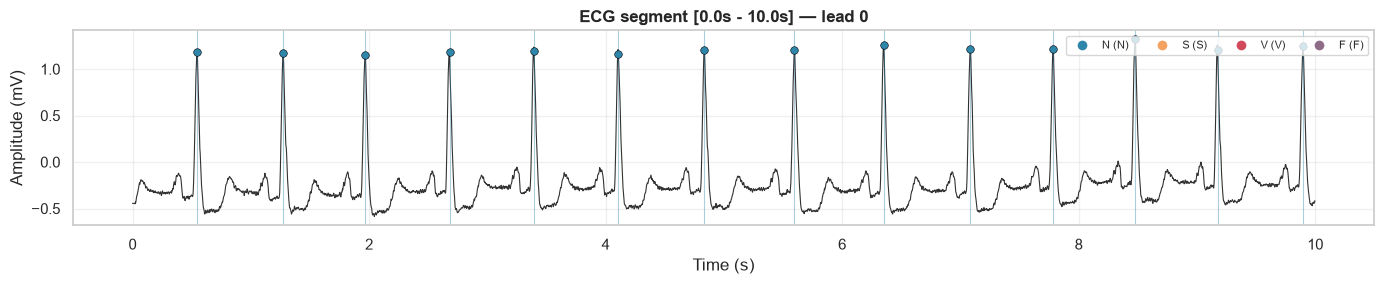

In [44]:
# Plot a 10-second window
fig = plot_ecg_segment(
    signal=signal,
    r_peaks=r_peaks,
    beat_labels=beat_labels,
    fs=fs,
    start_s=0.0,
    duration_s=10.0,
    lead=0,
)
save_figure(fig, f"../results/figures/02_ecg_segment_{RECORD_ID}.png")
plt.show()

### 3.1 A Second Lead for Cross-Validation

MIT-BIH records two leads: MLII (modified lead II) and V1 or V5. Lead 0 (MLII)
is usually the cleaner signal for QRS detection, while lead 1 provides complementary
morphology. Visualizing both leads on the same window confirms that R-peak
positions are consistent across channels — a sanity check for the segmentation.

[save_figure] Saved to ..\results\figures\03_ecg_segment_105_lead1.png


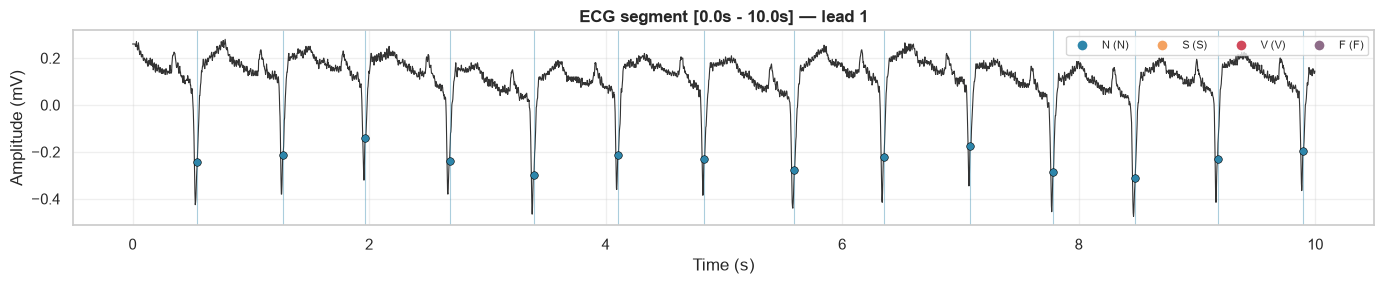

In [45]:
# Plot lead 1 for the same window
fig = plot_ecg_segment(
    signal=signal,
    r_peaks=r_peaks,
    beat_labels=beat_labels,
    fs=fs,
    start_s=0.0,
    duration_s=10.0,
    lead=1,
)
save_figure(fig, f"../results/figures/03_ecg_segment_{RECORD_ID}_lead1.png")
plt.show()

## 4. Beat Morphology by AAMI Class

The tabular features (RR interval, QRS width, amplitude, energy) summarize each
heartbeat into seven numbers. But the underlying signal is what a cardiologist reads.
This section visualizes representative beats from each AAMI class, extracted with
the same 200-before / 200-after window used by `extract_beats()`.

Visual hallmarks to look for:
- **N (Normal):** narrow QRS, regular P-wave before the QRS, consistent morphology.
- **S (Supraventricular ectopic):** early beat (short RR), usually narrow QRS but
  abnormal P-wave; often follows a compensatory pause.
- **V (Ventricular ectopic):** **wide, bizarre QRS**, no preceding P-wave, larger
  amplitude, often followed by a compensatory pause.
- **F (Fusion):** morphology intermediate between N and V (a supraventricular
  impulse fuses with a ventricular ectopic focus).

In [46]:
# Extract beats from the same record for visualization
from medical_preprocessing import extract_beats

beats, valid_idx = extract_beats(signal, r_peaks)
valid_labels = beat_labels[valid_idx]

print(f"Beats extracted: {beats.shape[0]}")
print(f"Beat window shape: {beats.shape[1:]}  (samples × leads)")
print(f"Class distribution in this record: {pd.Series(valid_labels).value_counts().to_dict()}")

Beats extracted: 2566
Beat window shape: (400, 2)  (samples × leads)
Class distribution in this record: {'N': 2525, 'V': 41}


[save_figure] Saved to ..\results\figures\04_representative_beats_105.png


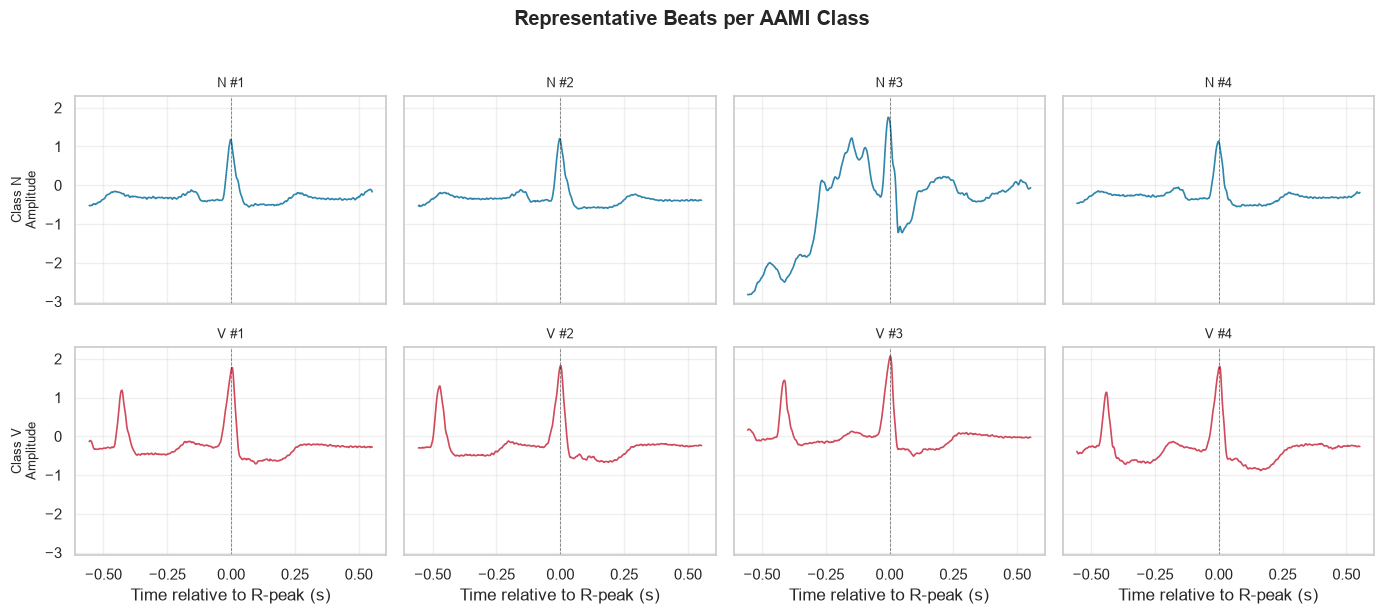

In [47]:
# Plot representative beats per class
fig = plot_representative_beats(
    beats=beats,
    labels=valid_labels,
    fs=fs,
    n_per_class=4,
)
save_figure(fig, f"../results/figures/04_representative_beats_{RECORD_ID}.png")
plt.show()

### 4.1 Why This Matters for the Medical Domain

In Workshop 5, the GAN generated synthetic housing records by learning the joint
distribution of 261 tabular features. In the medical domain, the same WGAN-GP
architecture can be re-purposed to generate **synthetic ventricular ectopic beats**
— but only if the morphological signal of V beats is meaningfully different from N.

The grid above provides qualitative evidence. The tabular analysis in the next
section will provide the quantitative counterpart: how separable are N and V
beats when projected onto the seven engineered features?

## 5. Tabular Feature Distributions by Class

The visual morphology analysis suggested that V beats have wider, more complex QRS
complexes than N beats. This section tests that hypothesis quantitatively: if the
seven engineered features are indeed discriminative, their distributions should
separate between Normal and Abnormal beats.

The key clinical features to examine are:
- **`qrs_width`:** should be larger for V beats (wide QRS > 120 ms vs narrow < 100 ms).
- **`qrs_amplitude`:** variable, but often larger for V due to abnormal depolarization.
- **`rr_prev` / `rr_next`:** V beats typically follow a compensatory pause, producing
  abnormal RR intervals.

[save_figure] Saved to ..\results\figures\05_feature_distributions.png


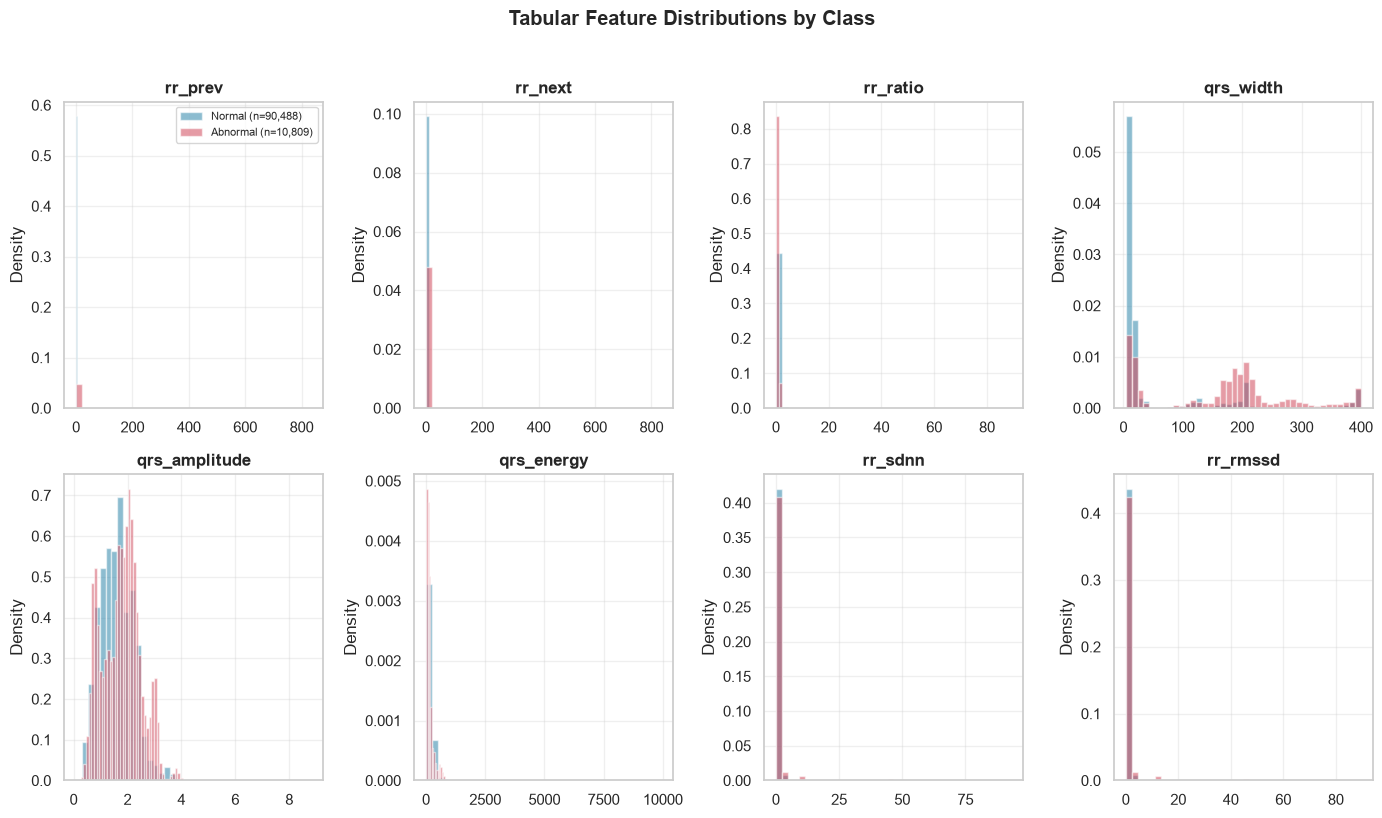

In [48]:
# Feature distributions by class (all 101k beats, not just record 105)
fig = plot_feature_distributions(df)
save_figure(fig, "../results/figures/05_feature_distributions.png")
plt.show()

### 5.1 Quantitative Separability

Beyond visual inspection, we can quantify how much each feature differs between
classes using a standardized mean difference (Cohen's *d*). Values above 0.8 indicate
large clinical effect sizes — the feature carries strong discriminative signal.

In [49]:
from scipy import stats

rows = []
for feat in FEATURE_COLUMNS:
    normal_vals = df.loc[df["label_binary"] == 0, feat].dropna()
    abnormal_vals = df.loc[df["label_binary"] == 1, feat].dropna()

    # Cohen's d (pooled standard deviation)
    n1, n2 = len(normal_vals), len(abnormal_vals)
    m1, m2 = normal_vals.mean(), abnormal_vals.mean()
    s1, s2 = normal_vals.std(ddof=1), abnormal_vals.std(ddof=1)
    pooled_std = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2))
    cohens_d = (m2 - m1) / pooled_std if pooled_std > 0 else np.nan

    # Mann-Whitney U test (non-parametric)
    _, p_value = stats.mannwhitneyu(normal_vals, abnormal_vals, alternative="two-sided")

    rows.append({
        "Feature":   feat,
        "Mean (N)":  f"{m1:.4f}",
        "Mean (Ab)": f"{m2:.4f}",
        "Cohen's d": f"{cohens_d:+.3f}",
        "p-value":   f"{p_value:.2e}",
    })

effect_df = pd.DataFrame(rows)
print(effect_df.to_string(index=False))

      Feature Mean (N) Mean (Ab) Cohen's d   p-value
      rr_prev   0.8362    0.9401    +0.031  0.00e+00
      rr_next   0.8057    1.1870    +0.113  4.53e-83
     rr_ratio   1.0788    0.7772    -0.415  0.00e+00
    qrs_width  63.4963  164.5309    +0.940  0.00e+00
qrs_amplitude   1.5942    1.7850    +0.308 6.02e-178
   qrs_energy 124.6741  149.2340    +0.149 2.10e-157
      rr_sdnn   0.3082    0.7059    +0.122  0.00e+00
     rr_rmssd   0.3594    0.8722    +0.158  0.00e+00


[save_figure] Saved to ..\results\figures\06_feature_correlation.png


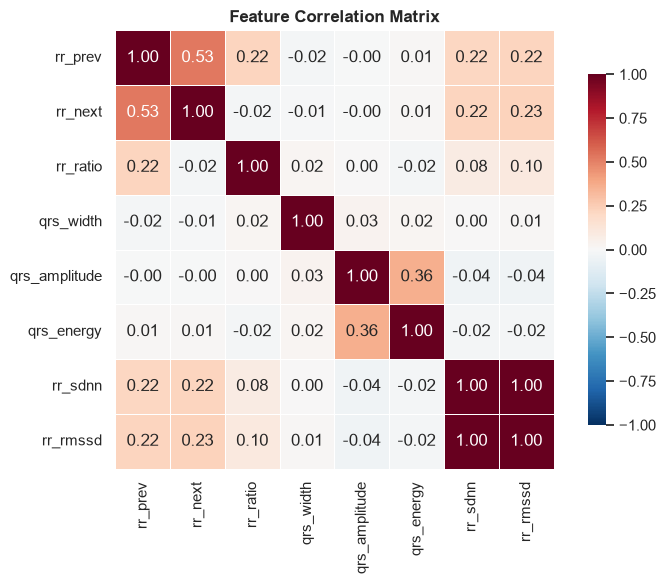

In [50]:
# Correlation heatmap
fig = plot_feature_correlation(df)
save_figure(fig, "../results/figures/06_feature_correlation.png")
plt.show()

## 6. Split Verification

With univariate analysis complete, we verify that the patient-level stratified split
preserves the global class balance. This is the final data-quality check before
transferring models from Workshops 1–5.

In [52]:
# Final verification table
print("=" * 65)
print("FINAL SPLIT VERIFICATION")
print("=" * 65)
print(f"Total beats: {len(df):,}")
print(f"Total records: {df['record_id'].nunique()}")
print(f"Global abnormal rate: {(df['label_binary'] == 1).mean():.4%}")
print()

for name, recs in [
    ("Train", splits.train_records),
    ("Val",   splits.val_records),
    ("Test",  splits.test_records),
]:
    sub = df[df["record_id"].isin(recs)]
    n_normal = int((sub["label_binary"] == 0).sum())
    n_abnormal = int((sub["label_binary"] == 1).sum())
    print(
        f"{name:5s} | Records: {sub['record_id'].nunique():2d} | "
        f"Beats: {len(sub):>6,} | "
        f"N: {n_normal:>6,} | Ab: {n_abnormal:>5,} | "
        f"Ab rate: {sub['label_binary'].mean():.2%}"
    )

# Sanity checks
assert df["label_binary"].isin([0, 1]).all(), "Labels must be binary"
assert df[FEATURE_COLUMNS].isna().sum().sum() == 0, "No NaN allowed"
print("\n All sanity checks passed.")

FINAL SPLIT VERIFICATION
Total beats: 101,297
Total records: 48
Global abnormal rate: 10.6706%

Train | Records: 34 | Beats: 69,455 | N: 61,972 | Ab: 7,483 | Ab rate: 10.77%
Val   | Records:  7 | Beats: 16,541 | N: 14,416 | Ab: 2,125 | Ab rate: 12.85%
Test  | Records:  7 | Beats: 15,301 | N: 14,100 | Ab: 1,201 | Ab rate: 7.85%

 All sanity checks passed.


## 7. Conclusions & Handoff to FASE 2

### Key findings

1. **Data pipeline validated:** 101,297 heartbeats from 48 MIT-BIH records were
   successfully extracted with seven tabular features. R-peak alignment and AAMI
   labeling were visually confirmed.

2. **Class imbalance is severe but manageable:** 89.3% Normal vs 10.7% Abnormal
   (8.4:1 ratio). Fusion beats (class F) are critically rare (0.79%, 802 beats),
   justifying synthetic augmentation via WGAN-GP in FASE 3.

3. **Patient-level stratified split preserves balance:** 68.6% / 16.3% / 15.1%
   of beats, with abnormality rates 10.77% / 12.85% / 7.85% — acceptable variance
   for threshold tuning.

4. **QRS width dominates univariate discrimination** (Cohen's d = 0.94), consistent
   with clinical knowledge. Other features contribute complementary signal:
   `rr_ratio` captures compensatory pauses (d = −0.42), while HRV features are
   patient-level and useful for stratification rather than beat-level classification.

### What transfers from Workshops 1–5

| Workshop | Component transferred | Medical role in FASE 2 |
|----------|-----------------------|------------------------|
| W1 | Tabular pipeline + Gradient Boosting | Baseline classification of beats |
| W2 | MLP with class weighting + threshold analysis | Main classifier |
| W3 | Concept of policy degeneration | Clinical deployment analysis |
| W4 | Autoencoder anomaly detection | Unsupervised anomaly scoring |
| W5 | WGAN-GP synthetic augmentation | Oversample rare V and F classes |

### Next steps (FASE 2)

- `src/transfer.py`: adapt W2 MLP and W4 AE to the 7-feature medical input.
- `src/medical_metrics.py`: sensitivity, specificity, PPV, NPV, threshold curves.
- `notebooks/02_transfer_training.ipynb`: train, validate, and compare.